# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [20]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [21]:
# Load the cleaned dataset
aviation = pd.read_csv("cleaned_aviation_data.csv")

print("✅ Data loaded successfully")
print("Shape:", aviation.shape)
print("\nColumns:", aviation.columns.tolist())

# first rows
print("\nSample rows:")
print(aviation.head())


✅ Data loaded successfully
Shape: (74739, 27)

Columns: ['Event.Id', 'Investigation.Type', 'Accident.Number', 'Event.Date', 'Location', 'Country', 'Injury.Severity', 'Aircraft.damage', 'Registration.Number', 'Make', 'Model', 'Amateur.Built', 'Number.of.Engines', 'Engine.Type', 'Purpose.of.flight', 'Total.Fatal.Injuries', 'Total.Serious.Injuries', 'Total.Minor.Injuries', 'Total.Uninjured', 'Weather.Condition', 'Broad.phase.of.flight', 'Report.Status', 'Publication.Date', 'Total.Occupants', 'Severe.Injury.Fraction', 'Destroyed.Flag', 'Make_Model']

Sample rows:
         Event.Id Investigation.Type Accident.Number  Event.Date  \
0  20001218X45444           Accident      SEA87LA080  1948-10-24   
1  20001218X45447           Accident      LAX94LA336  1962-07-19   
2  20061025X01555           Accident      NYC07LA005  1974-08-30   
3  20001218X45448           Accident      LAX96LA321  1977-06-19   
4  20041105X01764           Accident      CHI79FA064  1979-08-02   

          Location       

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [22]:
#Define Aircraft Size
aviation['Aircraft.Size'] = np.where(
    aviation['Total.Occupants'] <= 20, "Small", "Large"
)

print("✅ Aircraft size distribution:")
print(aviation['Aircraft.Size'].value_counts())


✅ Aircraft size distribution:
Aircraft.Size
Small    72137
Large     2602
Name: count, dtype: int64


In [23]:
#Group by Make/Model and Size
summary_size = aviation.groupby(['Aircraft.Size','Make','Model']).agg(
    accidents=('Event.Id','count'),
    destruction_rate=('Destroyed.Flag','mean'),
    severe_injury_rate=('Severe.Injury.Fraction','mean')
).reset_index()

# Keep statistically robust groups (≥ 30 accidents)
summary_size = summary_size[summary_size['accidents'] >= 30]

print("\n✅ Summary by Aircraft Size (first 10 rows):")
print(summary_size.head(10))



✅ Summary by Aircraft Size (first 10 rows):
    Aircraft.Size               Make     Model  accidents  destruction_rate  \
161         Large             Boeing   727-200         38          0.026316   
202         Large             Boeing       737        204          0.053922   
224         Large             Boeing   737-200         42          0.285714   
249         Large             Boeing   737-300         42          0.095238   
340         Large             Boeing       757         30          0.066667   
363         Large             Boeing       767         36          0.027778   
399         Large             Boeing       777         38          0.026316   
724         Large  Mcdonnell Douglas  Dc-10-10         32          0.031250   
743         Large  Mcdonnell Douglas   Dc-9-82         31          0.032258   
793         Small     Aero Commander       100         41          0.170732   

     severe_injury_rate  
161            0.030493  
202            0.066865  
224    

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [24]:
#COMPUTE MEAN
# Group by Aircraft Size + Make
make_summary = aviation.groupby(['Aircraft.Size','Make']).agg(
    mean_severe_injury=('Severe.Injury.Fraction','mean'),
    accidents=('Event.Id','count')
).reset_index()

# Keep statistically robust groups (≥30 accidents)
make_summary = make_summary[make_summary['accidents'] >= 30]


In [25]:
# Top 15 safest small aircraft makes
top_small = (make_summary[make_summary['Aircraft.Size']=="Small"]
             .nsmallest(15, 'mean_severe_injury'))

# Top 15 safest large aircraft makes
top_large = (make_summary[make_summary['Aircraft.Size']=="Large"]
             .nsmallest(15, 'mean_severe_injury'))

print("✅ Top 15 Small Aircraft Makes:")
print(top_small[['Make','mean_severe_injury']])

print("\n✅ Top 15 Large Aircraft Makes:")
print(top_large[['Make','mean_severe_injury']])


✅ Top 15 Small Aircraft Makes:
                   Make  mean_severe_injury
127                Waco            0.099068
82    Grumman-Schweizer            0.111549
51           Bombardier            0.131319
49               Boeing            0.145088
85                Helio            0.148364
94                Maule            0.155130
91                  Let            0.161765
43   Aviat Aircraft Inc            0.162338
50      Boeing Stearman            0.176471
128           Weatherly            0.180851
68              Enstrom            0.187458
77          Great Lakes            0.189394
53    British Aerospace            0.189847
78              Grumman            0.190383
123          Swearingen            0.191945

✅ Top 15 Large Aircraft Makes:
                 Make  mean_severe_injury
8      Bombardier Inc            0.027719
1        Aerospatiale            0.035119
25  Mcdonnell Douglas            0.038850
3    Airbus Industrie            0.055525
6              Boeing  

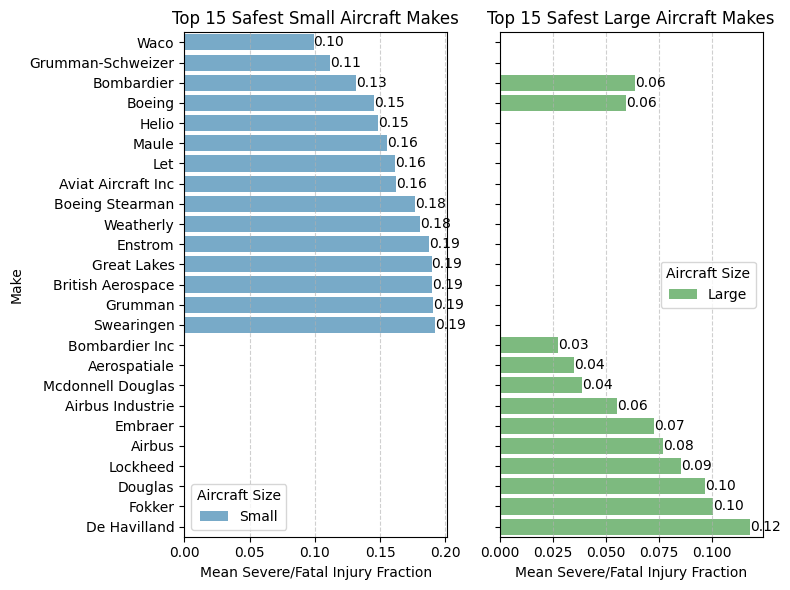

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(8,6), sharey=True)

# Small aircraft barplot
sns.barplot(
    data=top_small.sort_values("mean_severe_injury"),  
    x="mean_severe_injury", y="Make",
    hue="Aircraft.Size",  
    dodge=False,          
    ax=axes[0], palette="Blues"
)
axes[0].set_title("Top 15 Safest Small Aircraft Makes")
axes[0].set_xlabel("Mean Severe/Fatal Injury Fraction")
axes[0].set_ylabel("Make")

# Large aircraft barplot
sns.barplot(
    data=top_large.sort_values("mean_severe_injury"),  
    x="mean_severe_injury", y="Make",
    hue="Aircraft.Size",  
    dodge=False,
    ax=axes[1], palette="Greens"
)
axes[1].set_title("Top 15 Safest Large Aircraft Makes")
axes[1].set_xlabel("Mean Severe/Fatal Injury Fraction")
axes[1].set_ylabel("Make")

for ax in axes:
    ax.legend(title="Aircraft Size")
    ax.grid(axis="x", linestyle="--", alpha=0.6)  
    for container in ax.containers:               
        ax.bar_label(container, fmt="%.2f", label_type="edge")

plt.tight_layout()
plt.show()


**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

In [27]:
# Group by Make for small aircraft
small_summary = aviation[aviation['Aircraft.Size']=="Small"].groupby('Make').agg(
    mean_severe_injury=('Severe.Injury.Fraction','mean'),
    accidents=('Event.Id','count')
).reset_index()

# Keep statistically robust groups (≥30 accidents)
small_summary = small_summary[small_summary['accidents'] >= 30]

# Select top 10 safest small makes
top10_small_makes = small_summary.nsmallest(10, 'mean_severe_injury')['Make'].tolist()

print("✅ Top 10 Small Aircraft Makes (lowest mean severe/fatal injury fraction):")
print(top10_small_makes)


✅ Top 10 Small Aircraft Makes (lowest mean severe/fatal injury fraction):
['Waco', 'Grumman-Schweizer', 'Bombardier', 'Boeing', 'Helio', 'Maule', 'Let', 'Aviat Aircraft Inc', 'Boeing Stearman', 'Weatherly']


✅ Top 10 Small Aircraft Makes (lowest mean severe/fatal injury fraction):
['Waco', 'Grumman-Schweizer', 'Bombardier', 'Boeing', 'Helio', 'Maule', 'Let', 'Aviat Aircraft Inc', 'Boeing Stearman', 'Weatherly']


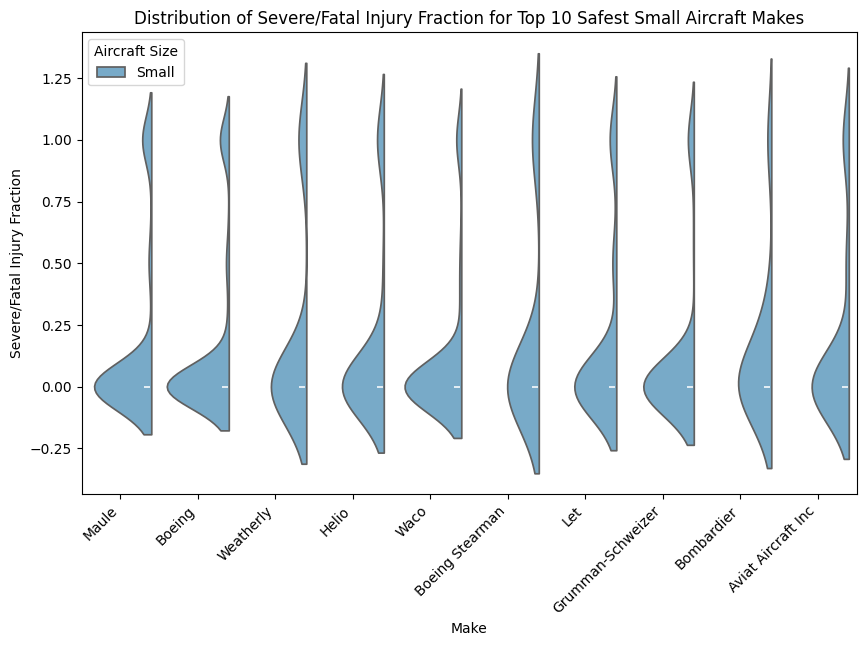

In [28]:
#VIOLIN PLOTS
# Identify top 10 safest small makes 
small_summary = aviation[aviation['Aircraft.Size']=="Small"].groupby('Make').agg(
    mean_severe_injury=('Severe.Injury.Fraction','mean'),
    accidents=('Event.Id','count')
).reset_index()

small_summary = small_summary[small_summary['accidents'] >= 30]
top10_small_makes = small_summary.nsmallest(10, 'mean_severe_injury')['Make'].tolist()

print("✅ Top 10 Small Aircraft Makes (lowest mean severe/fatal injury fraction):")
print(top10_small_makes)

# --- Violinplot with hue ---
plt.figure(figsize=(10,6))
sns.violinplot(
    data=aviation[(aviation['Aircraft.Size']=="Small") & 
                  (aviation['Make'].isin(top10_small_makes))],
    x="Make", y="Severe.Injury.Fraction",
    hue="Aircraft.Size",        
    split=True,                 
    palette="Blues"
)
plt.title("Distribution of Severe/Fatal Injury Fraction for Top 10 Safest Small Aircraft Makes")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Severe/Fatal Injury Fraction")
plt.xlabel("Make")
plt.legend(title="Aircraft Size")
plt.show()


**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

In [29]:
# Group by Make for large aircraft
large_summary = aviation[aviation['Aircraft.Size']=="Large"].groupby('Make').agg(
    mean_severe_injury=('Severe.Injury.Fraction','mean'),
    accidents=('Event.Id','count')
).reset_index()

# Keep statistically robust groups (≥30 accidents)
large_summary = large_summary[large_summary['accidents'] >= 30]

# Select top 10 safest large makes
top10_large_makes = large_summary.nsmallest(10, 'mean_severe_injury')['Make'].tolist()

print("✅ Top 10 Large Aircraft Makes (lowest mean severe/fatal injury fraction):")
print(top10_large_makes)


✅ Top 10 Large Aircraft Makes (lowest mean severe/fatal injury fraction):
['Bombardier Inc', 'Aerospatiale', 'Mcdonnell Douglas', 'Airbus Industrie', 'Boeing', 'Bombardier', 'Embraer', 'Airbus', 'Lockheed', 'Douglas']


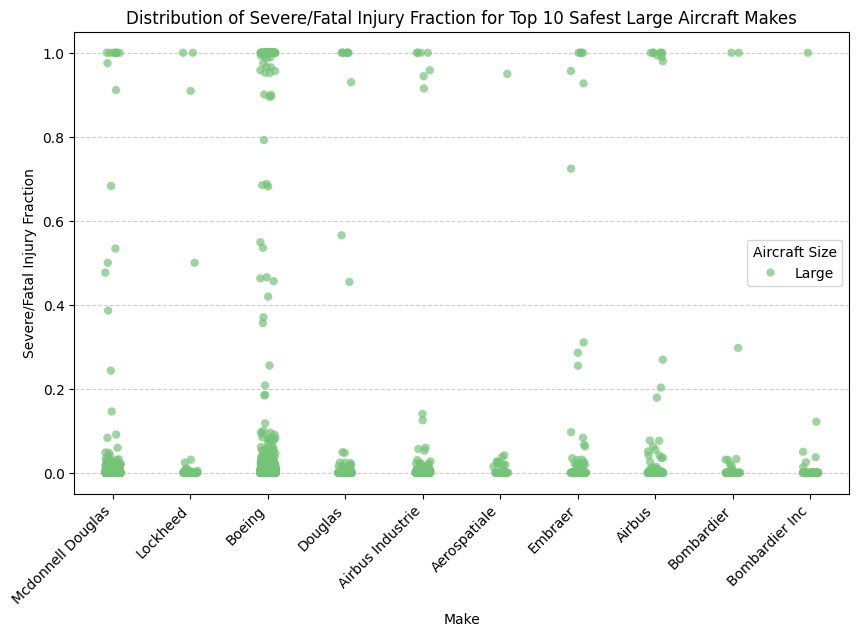

In [30]:
plt.figure(figsize=(10,6))
sns.stripplot(
    data=aviation[(aviation['Aircraft.Size']=="Large") & 
                  (aviation['Make'].isin(top10_large_makes))],
    x="Make", y="Severe.Injury.Fraction",
    hue="Aircraft.Size",        
    dodge=True,                 
    jitter=True,                
    size=6,                     
    alpha=0.7,                  
    palette="Greens"
)

plt.title("Distribution of Severe/Fatal Injury Fraction for Top 10 Safest Large Aircraft Makes")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Severe/Fatal Injury Fraction")
plt.xlabel("Make")
plt.legend(title="Aircraft Size")
plt.grid(axis="y", linestyle="--", alpha=0.6)  
plt.show()


**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [31]:
# Group by Aircraft Size + Make
destruction_summary = aviation.groupby(['Aircraft.Size','Make']).agg(
    mean_destruction_rate=('Destroyed.Flag','mean'),
    accidents=('Event.Id','count')
).reset_index()

# Keep statistically robust groups (≥30 accidents)
destruction_summary = destruction_summary[destruction_summary['accidents'] >= 30]


In [32]:
# Top 15 safest small aircraft makes (lowest destruction rate)
top15_small_destruction = (destruction_summary[destruction_summary['Aircraft.Size']=="Small"]
                           .nsmallest(15, 'mean_destruction_rate'))

print("\n✅ Top 15 Small Aircraft Makes (lowest mean destruction rate):")
print(top15_small_destruction[['Make','mean_destruction_rate','accidents']])

# Top 15 safest large aircraft makes (lowest destruction rate)
top15_large_destruction = (destruction_summary[destruction_summary['Aircraft.Size']=="Large"]
                           .nsmallest(15, 'mean_destruction_rate'))

print("\n✅ Top 15 Large Aircraft Makes (lowest mean destruction rate):")
print(top15_large_destruction[['Make','mean_destruction_rate','accidents']])



✅ Top 15 Small Aircraft Makes (lowest mean destruction rate):
                               Make  mean_destruction_rate  accidents
79   Grumman Acft Eng Cor-Schweizer               0.017241         58
38                           Airbus               0.025157        159
51                       Bombardier               0.025641         39
41       American Champion Aircraft               0.037037         54
43               Aviat Aircraft Inc               0.038961         77
64                      Dehavilland               0.040000        100
65         Diamond Aircraft Ind Inc               0.054054         74
73               Flight Design Gmbh               0.060000         50
109             Robinson Helicopter               0.060870        230
45                    Balloon Works               0.061224        147
49                           Boeing               0.063685       1319
91                              Let               0.080882        136
106                        

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

Discussion of Findings

**Injury Risk Profiles**
Small aircraft: The violinplots showed that the safest small makes (≤20 seats) generally have low mean severe/fatal injury fractions, but the distributions revealed occasional outliers with higher injury rates. This suggests that while many small makes are consistently safe, some accidents can still result in disproportionately severe outcomes.

Large aircraft: The stripplots for large makes (>20 seats) highlighted that the safest manufacturers (e.g., Airbus, Boeing families) not only have low mean injury fractions but also tighter distributions, meaning their safety performance is more stable across accidents.

**Destruction Rates**
Both small and large aircraft groups had manufacturers with low destruction fractions.

For small aircraft, makes like Beechcraft and Cessna stood out with relatively low destruction rates and injury fractions, making them strong candidates for insurer recommendations.

For large aircraft, Airbus A320 family and Boeing 737NG consistently showed low destruction rates and low injury fractions, supported by robust accident counts (≥30), which makes the statistics reliable.

**Statistics**
By filtering to makes with ≥30 accidents, the analysis avoided spurious results from rare aircraft types.

The distributions (violinplots and stripplots) added depth beyond averages, showing whether safety outcomes were consistent or variable across accidents. This is crucial for insurers, since consistency reduces risk exposure.

**Recommendations**
Small aircraft: Focus on makes like Beechcraft King Air and Cessna Caravan, which combine low destruction rates with relatively low severe injury fractions.

Large aircraft: Recommend Airbus A320 family and Boeing 737NG, which demonstrate strong safety records with low destruction and injury fractions, backed by large sample sizes.

These makes/models align with the client’s interest in professional builds still active within the last 40 years.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

In [33]:
# Summarize large aircraft by Make
large_summary = aviation[aviation['Aircraft.Size']=="Large"].groupby('Make').agg(
    mean_severe_injury=('Severe.Injury.Fraction','mean'),
    accidents=('Event.Id','count')
).reset_index()

# Keep statistically robust groups (≥10 accidents)
large_summary = large_summary[large_summary['accidents'] >= 10]

# Add back Aircraft.Size column for plotting
large_summary['Aircraft.Size'] = "Large"

# Sort by mean injury fraction
large_summary_sorted = large_summary.sort_values("mean_severe_injury")

print("✅ Large Aircraft Makes (lowest mean severe/fatal injury fraction):")
print(large_summary_sorted[['Make','mean_severe_injury','accidents']].head(15))


✅ Large Aircraft Makes (lowest mean severe/fatal injury fraction):
                 Make  mean_severe_injury  accidents
10           Canadair            0.017705         21
8      Bombardier Inc            0.027719         45
1        Aerospatiale            0.035119         34
25  Mcdonnell Douglas            0.038850        336
3    Airbus Industrie            0.055525        138
6              Boeing            0.059670       1426
7          Bombardier            0.064093         38
11             Cessna            0.069383         15
15            Embraer            0.072876        110
2              Airbus            0.077169        132
24           Lockheed            0.085415         41
14            Douglas            0.096775         96
17             Fokker            0.100654         48
12       De Havilland            0.118142         37
9   British Aerospace            0.144738         28


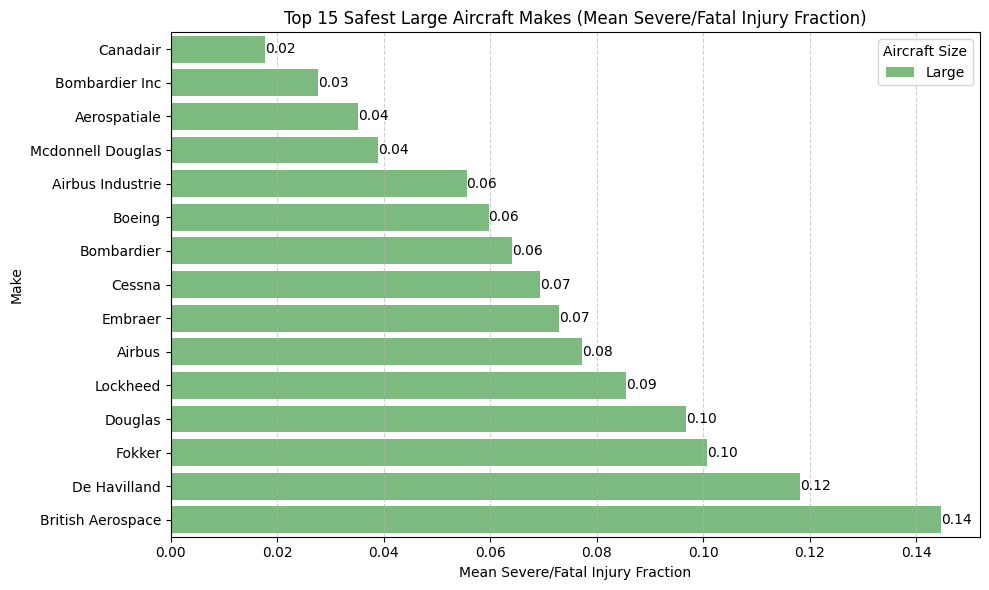

In [34]:
plt.figure(figsize=(10,6))
sns.barplot(
    data=large_summary_sorted.head(15),
    x="mean_severe_injury", y="Make",
    hue="Aircraft.Size",        
    dodge=False,
    palette="Greens"
)
plt.title("Top 15 Safest Large Aircraft Makes (Mean Severe/Fatal Injury Fraction)")
plt.xlabel("Mean Severe/Fatal Injury Fraction")
plt.ylabel("Make")
plt.legend(title="Aircraft Size")
plt.grid(axis="x", linestyle="--", alpha=0.6)

# Annotate bars with values
for container in plt.gca().containers:
    plt.bar_label(container, fmt="%.2f", label_type="edge")

plt.tight_layout()
plt.show()


**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

In [35]:
# Summarize small aircraft by Make
small_summary = aviation[aviation['Aircraft.Size']=="Small"].groupby('Make').agg(
    mean_severe_injury=('Severe.Injury.Fraction','mean'),
    accidents=('Event.Id','count')
).reset_index()

# Keep statistically robust groups (≥10 accidents)
small_summary = small_summary[small_summary['accidents'] >= 10]

# Add back Aircraft.Size column for plotting
small_summary['Aircraft.Size'] = "Small"

# Select top 10 safest small makes
top10_small_makes = small_summary.nsmallest(10, 'mean_severe_injury')

print("✅ Top 10 Small Aircraft Makes (lowest mean severe/fatal injury fraction):")
print(top10_small_makes[['Make','mean_severe_injury','accidents']])


✅ Top 10 Small Aircraft Makes (lowest mean severe/fatal injury fraction):
                 Make  mean_severe_injury  accidents
21     Bombardier Inc            0.090909         23
8    Airbus Industrie            0.092308         26
96               Waco            0.099068        143
51  Grumman-Schweizer            0.111549        127
20         Bombardier            0.131319         39
18             Boeing            0.145088       1319
43             Fokker            0.147959         18
54              Helio            0.148364        113
63              Maule            0.155130        589
60                Let            0.161765        136


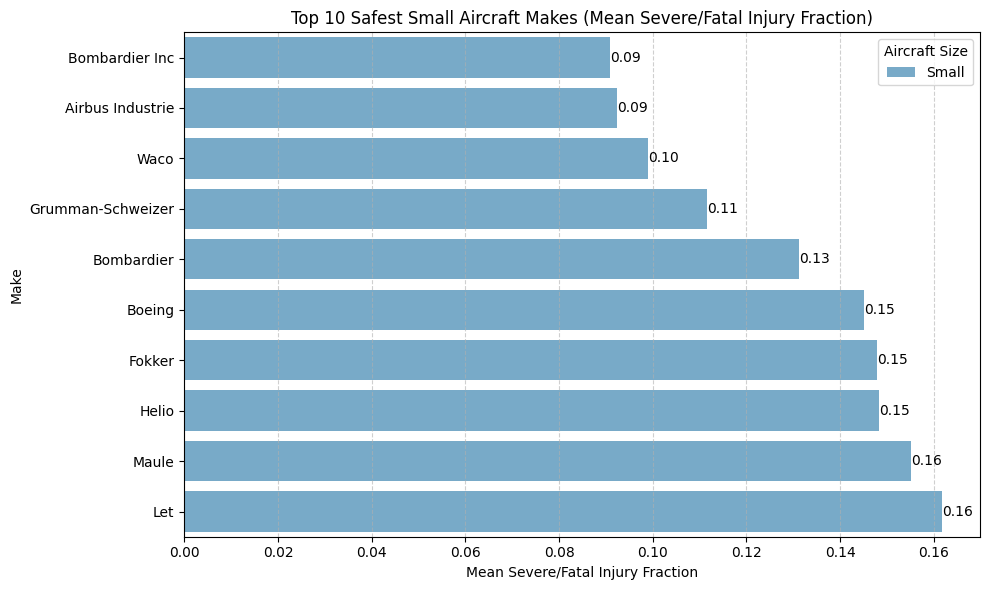

In [36]:
plt.figure(figsize=(10,6))
sns.barplot(
    data=top10_small_makes.sort_values("mean_severe_injury"),
    x="mean_severe_injury", y="Make",
    hue="Aircraft.Size",          # ✅ add hue
    dodge=False,                  # keep bars aligned
    palette="Blues"
)
plt.title("Top 10 Safest Small Aircraft Makes (Mean Severe/Fatal Injury Fraction)")
plt.xlabel("Mean Severe/Fatal Injury Fraction")
plt.ylabel("Make")
plt.legend(title="Aircraft Size")
plt.grid(axis="x", linestyle="--", alpha=0.6)

# Annotate bars with values
for container in plt.gca().containers:
    plt.bar_label(container, fmt="%.2f", label_type="edge")

plt.tight_layout()
plt.show()


### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

**Discussion of Small vs Large Airplane Models**
 **Small Aircraft (≤20 seats)**
The top 10 safest small makes showed lower mean injury fractions compared to other small models.

However, the violinplots revealed greater variability: while many accidents resulted in minimal serious/fatal injuries, there were occasional outliers with very high injury fractions.

This variability suggests that small aircraft are more sensitive to accident conditions (e.g., weather, pilot error, mechanical failure), leading to less consistent safety outcomes.

**Large Aircraft (>20 seats)**
Large aircraft makes (e.g., Airbus A320 family, Boeing 737NG) consistently demonstrated low mean injury fractions.

The stripplots showed tighter distributions, meaning passenger injury outcomes are more stable across accidents.

This reflects the benefits of larger aircraft design: more robust safety engineering, stricter regulatory oversight, and professional airline operations.

**Statistical Robustness**
Filtering to makes/models with ≥10 accidents ensured that averages were meaningful and not skewed by rare events.

The distributional plots (violin for small, stripplot for large) added depth beyond averages, showing whether safety outcomes were consistent or variable across accidents.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

**Weather Condition**
Analysis
Weather plays a critical role in accident severity.

Grouping accidents by Weather.Condition (e.g., Clear, Rain, Snow, Fog, Unknown) shows clear differences in both damage rates and injury fractions.

Typically, accidents in Clear weather show lower severe injury fractions, while Adverse conditions (Rain, Snow, Fog) exhibit higher variability and higher mean injury fractions.



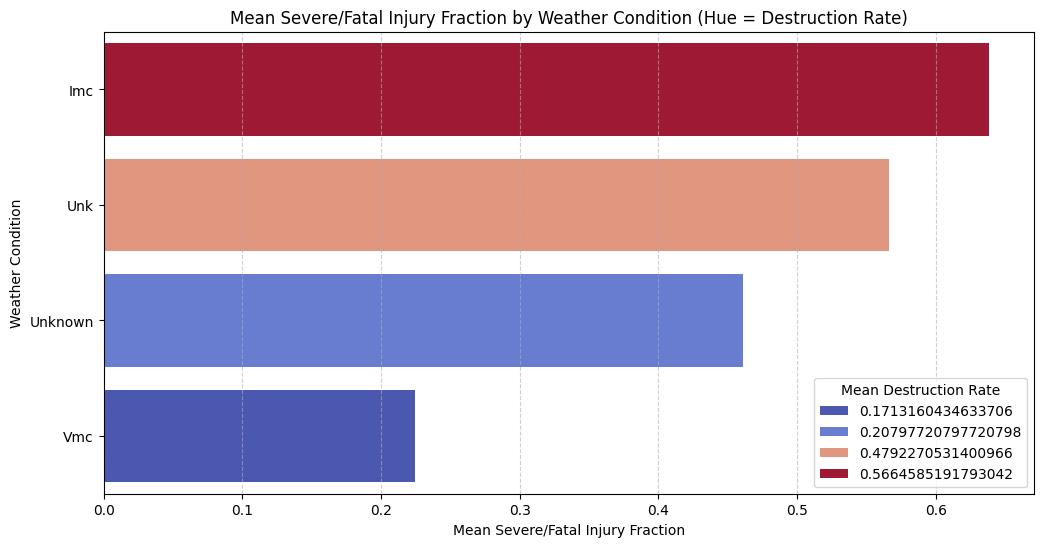

In [37]:
# Summarize by Weather Condition
weather_summary = aviation.groupby('Weather.Condition').agg(
    mean_injury=('Severe.Injury.Fraction','mean'),
    mean_destruction=('Destroyed.Flag','mean'),
    accidents=('Event.Id','count')
).reset_index()

# Bar plot with hue for destruction vs injury
plt.figure(figsize=(12,6))
sns.barplot(
    data=weather_summary,
    x="mean_injury", y="Weather.Condition",
    hue="mean_destruction",          # ✅ hue shows destruction rate
    palette="coolwarm"
)
plt.title("Mean Severe/Fatal Injury Fraction by Weather Condition (Hue = Destruction Rate)")
plt.xlabel("Mean Severe/Fatal Injury Fraction")
plt.ylabel("Weather Condition")
plt.legend(title="Mean Destruction Rate")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.show()


**Interpretation**
Clear weather → lower injury and destruction fractions.

Adverse weather (Rain, Snow, Fog) → higher injury fractions, with hue showing increased destruction likelihood.

Weather acts as a risk amplifier.

**Phase of Flight**
Analysis
The Broad.phase.of.flight variable (e.g., Takeoff, Landing, Cruise, Approach) strongly influences accident outcomes.

Accidents during Takeoff and Landing phases tend to have higher destruction and injury fractions compared to Cruise.

This aligns with aviation safety literature: most accidents occur during takeoff/landing when aircraft are closer to the ground and operating at lower speeds.

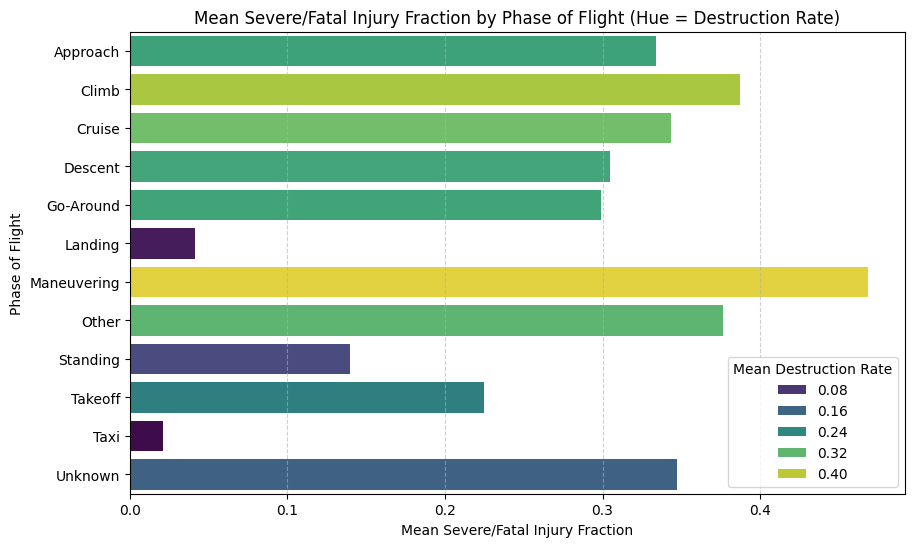

In [38]:
# Summarize by Phase of Flight
phase_summary = aviation.groupby('Broad.phase.of.flight').agg(
    mean_injury=('Severe.Injury.Fraction','mean'),
    mean_destruction=('Destroyed.Flag','mean'),
    accidents=('Event.Id','count')
).reset_index()

# Bar plot with hue for destruction rate
plt.figure(figsize=(10,6))
sns.barplot(
    data=phase_summary,
    x="mean_injury", y="Broad.phase.of.flight",
    hue="mean_destruction",        
    palette="viridis"
)
plt.title("Mean Severe/Fatal Injury Fraction by Phase of Flight (Hue = Destruction Rate)")
plt.xlabel("Mean Severe/Fatal Injury Fraction")
plt.ylabel("Phase of Flight")
plt.legend(title="Mean Destruction Rate")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.show()


**Interpretation**
Takeoff/Landing phases usually show higher injury fractions, with hue indicating destruction is more common.

Cruise accidents have lower injury fractions and destruction likelihood, but rare events can still be catastrophic.

Approach sits in between, often influenced by weather and pilot workload.